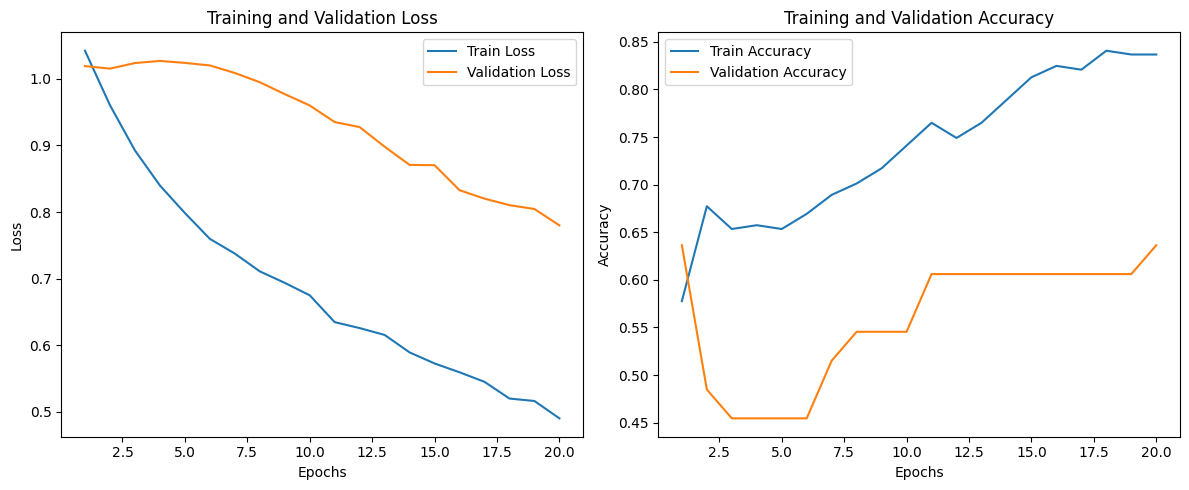

In [14]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets
from torch.utils.data import DataLoader
from torchvision.models import resnet50, ResNet50_Weights
import torch.nn.functional as F
import matplotlib.pyplot as plt
import torchmetrics
from torch.utils.data import Dataset
from PIL import Image
from pathlib import Path

class MexCultureDataset(Dataset):
    def __init__(self, root_dir, transform=None):

        self.transform = transform
        self.classes = ["Prehispanic", "Colonial", "Modern"]
        self.samples = []
        
        for file_path in Path(root_dir).iterdir():
            if file_path.is_file():
                path_str = str(file_path)
                filename = file_path.name
                
                if filename.startswith("Prehispanic"):
                    self.samples.append((path_str, 0))
                elif filename.startswith("Colonial"):
                    self.samples.append((path_str, 1))
                elif filename.startswith("Modern"):
                    self.samples.append((path_str, 2))
                    
    def __len__(self):
        return len(self.samples)
        
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert("RGB")
        
        if self.transform:
            image = self.transform(image)
            
        return image, label

#dt_train = "/net/ens/DeepLearning/DLCV2026/MexCulture142/images_train" Décommenter si au CREMI
#dt_val = "/net/ens/DeepLearning/DLCV2026/MexCulture142/images_val" Décommenter si au CREMI

dt_train = "MexCulture142/images_train" #Commenter si au CREMI
dt_val = "MexCulture142/images_val" #Commenter si au CREMI

#model = torch.hub.load("pytorch/vision", "resnet50", weights="IMAGENET1K_V2")

weights = ResNet50_Weights.DEFAULT # par défaut c'est la V2 avec 80% d'accuracy
model = resnet50(weights=weights)

for param in model.parameters(): #on gèle les couches de bases
    param.requires_grad = False

model.fc = nn.Linear(model.fc.in_features, 3) # On remplace la dernière couche par une de 3 neurones pour notre classification

preprocess = weights.transforms()

train_dataset = MexCultureDataset(root_dir=dt_train, transform=preprocess)
val_dataset = MexCultureDataset(root_dir=dt_val, transform=preprocess)

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0 #Augmenter si au CREMI
)

val_loader = DataLoader(
    dataset=val_dataset,
    batch_size=32,
    shuffle=False, 
    num_workers=0 #Augmeter au CREMI
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(),lr=1e-4) #on ne donne que la couche finale à l'optimizer

train_acc_metric = torchmetrics.Accuracy(task="multiclass", num_classes=3).to(device)
val_acc_metric = torchmetrics.Accuracy(task="multiclass", num_classes=3).to(device)
train_loss_metric = torchmetrics.MeanMetric().to(device)
val_loss_metric = torchmetrics.MeanMetric().to(device)

num_epochs = 20
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

for epoch in range(num_epochs):
    model.train()
    running_loss, correct_train, total_train = 0.0, 0, 0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss_metric.update(loss)
        train_acc_metric.update(outputs, labels) 
        
    model.eval()    
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_metric.update(loss)
            val_acc_metric.update(outputs, labels)  

    history['train_loss'].append(train_loss_metric.compute().item())
    history['train_acc'].append(train_acc_metric.compute().item())
    history['val_loss'].append(val_loss_metric.compute().item())
    history['val_acc'].append(val_acc_metric.compute().item())

    #On remet à zéro pour l'époch suivante
    train_loss_metric.reset()
    train_acc_metric.reset()
    val_loss_metric.reset()
    val_acc_metric.reset()

epochs_range = range(1, num_epochs + 1)

plt.figure(figsize=(12, 5))

# Courbes loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['train_loss'], label='Train Loss')
plt.plot(epochs_range, history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Courbes accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['train_acc'], label='Train Accuracy')
plt.plot(epochs_range, history['val_acc'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()